In [2]:
# 필요한 도구 불러오기

import numpy as np                 # 넘파이: 숫자 계산
import pandas as pd                # 판다스: 데이터 표 관리
import matplotlib.pyplot as plt    # 맷플롯립: 그래프 그리기
from sklearn.preprocessing import MinMaxScaler  # 민맥스 스케일러: 숫자 범위 맞추기
from tensorflow.keras.models import Sequential  # 시퀀셜: 모델 층 쌓기
from tensorflow.keras.layers import SimpleRNN, Dense  # 심플 알엔엔: 순서 기억 / 덴스: 최종 예측

In [3]:
# 1. 데이터 불러오기

file_path = "dataset/jena_climate_2009.csv"  # 파일 경로: 기온 데이터 위치
data = pd.read_csv(file_path)                # read_csv(리드 씨에스브이): CSV 파일을 표로 읽기

# 🍔 재료 창고에서 기온 데이터 표를 가져오는 단계

In [ ]:
# 데이터 확인
# Date Time(데이트 타임): 관측 날짜와 시간
# p (mbar): 기압 / T (degC): 기온
# Tpot (K): 잠재온도

data.head()  # 헤드: 데이터의 처음 5개 행 확인

# 🍔 재료 창고에서 가져온 기온 데이터의 앞부분을 살펴보는 단계

In [4]:
data.shape


(21743, 15)

In [5]:
# T (degC): 기온 데이터 선택
temperature = data['T (degC)'].values
# values(밸류즈): 표에서 실제 숫자만 가져오기
# temperature(템퍼러처): 기온 데이터 저장 변수

# 🍔 전체 재료 중 기온 재료만 골라 담는 단계

In [6]:
# 2. 데이터 전처리
scaler = MinMaxScaler(feature_range=(0, 1))  # 민맥스 스케일러: 숫자를 0~1 범위로 변환

scaled_data = scaler.fit_transform(temperature.reshape(-1, 1))
# reshape(리셰이프): 데이터를 세로 한 줄 형태로 변경
# fit_transform(핏 트랜스폼): 최솟값과 최댓값을 찾고 0~1로 변환

# 🍔 재료의 양을 일정한 기준으로 맞춰 요리하기 쉽게 만드는 단계

In [7]:
# 데이터셋 생성 함수
# look_back(룩백): 과거 몇 개의 데이터를 볼지 정하는 값 (60개)

def create_dataset(dataset, look_back=60):
    X, y = [], []  # X: 과거 기온 / y: 다음 기온 정답

    for i in range(len(dataset) - look_back):
        X.append(dataset[i:i + look_back, 0])  # 과거 60개 기온 저장
        y.append(dataset[i + look_back, 0])    # 다음 기온 저장

    return np.array(X), np.array(y)  # 넘파이 배열로 변환

# 🍔 과거 60개의 기온을 보고 다음 기온을 맞히는 문제 만들기

In [8]:
# 과거 60분 데이터를 기반으로 다음 기온 예측
look_back = 60  # 룩백: 과거 60개 데이터 사용

X, y = create_dataset(scaled_data, look_back)
# X: 과거 60개 기온 데이터
# y: 다음 기온 정답 데이터

X = np.reshape(X, (X.shape[0], X.shape[1], 1))
# reshape(리셰이프): RNN이 읽을 수 있는 3차원 형태로 변경
# (전체 데이터 수, 과거 데이터 수, 특성 수)

# 🍔 과거 60분의 기온을 한 묶음으로 만들어 요리사(RNN)에게 전달

In [9]:
# X 데이터의 크기 확인
X.shape  # (전체 데이터 묶음 수, 과거 데이터 수, 특성 수)
# 결과 예: (전체 개수, 60, 1)
# 60: 과거 60개 기온
# 1: 기온이라는 특성 1개

# 🍔 요리할 재료 묶음이 몇 개이고, 각 묶음에 재료가 몇 개인지 확인

(21683, 60, 1)

In [10]:
# 데이터 분리
train_size = int(len(X) * 0.8)  # 전체 데이터의 80%를 학습용으로 사용

X_train, X_test = X[:train_size], X[train_size:]
# X_train: 학습용 과거 기온 데이터
# X_test: 테스트용 과거 기온 데이터

y_train, y_test = y[:train_size], y[train_size:]
# y_train: 학습용 정답 기온
# y_test: 테스트용 정답 기온

# int(인트): 소수점 버리고 정수로 변환
# 🍔 전체 재료 묶음 중 80%는 요리 연습, 20%는 실력 시험에 사용


In [11]:
# 3. RNN 모델 구성
model = Sequential([
    SimpleRNN(50, return_sequences=False, input_shape=(X.shape[1], 1)),
    # SimpleRNN(심플 알엔엔): 과거 데이터의 흐름을 기억하며 학습
    # 50: 뉴런(기억 단위) 50개
    # return_sequences=False: 마지막 시점의 결과만 전달
    # input_shape: 입력 데이터 형태 (과거 60개, 특성 1개)

    Dense(1)  # 덴스: 최종 기온 예측값 1개 출력
])

# 🍔 RNN 요리사가 과거 60분의 기온을 살펴보고 다음 기온 하나를 내놓는 구조

c:\Users\human-01\OneDrive\Desktop\Python_AI_Lab\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
# RNN 모델 학습 설정
model.compile(
    optimizer='adam',  # 옵티마이저(옵티마이저): 오차를 줄이도록 학습 방법 설정
    loss='mean_squared_error'  # 평균 제곱 오차: 예측 기온과 실제 기온의 차이 계산
)

# 🍔 요리사가 맛을 보고 실제 맛과 얼마나 차이 나는지 채점하는 기준 설정

In [13]:
# 4. 모델 학습
history = model.fit(
    X_train, y_train,  # 학습용 기온 데이터와 정답
    epochs=20,         # 에포크: 전체 학습 데이터를 20번 반복
    batch_size=32,     # 배치 사이즈: 한 번에 32개씩 학습
    validation_data=(X_test, y_test),  # 학습 중 테스트 데이터로 확인
    shuffle=False      # 셔플: 시간 순서가 중요하므로 섞지 않음
)

# history(히스토리): 학습 과정과 결과 기록
# 🍔 요리사가 20번 연습하고, 32개씩 나눠 요리하는 단계

Epoch 1/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.0034 - val_loss: 1.9667e-04
Epoch 2/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 1.8152e-04 - val_loss: 1.3185e-04
Epoch 3/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 1.2167e-04 - val_loss: 9.9431e-05
Epoch 4/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 8.5226e-05 - val_loss: 1.4830e-04
Epoch 5/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 6.9692e-05 - val_loss: 1.4984e-04
Epoch 6/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 6.1193e-05 - val_loss: 1.1893e-04
Epoch 7/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 5.8087e-05 - val_loss: 1.0523e-04
Epoch 8/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 5.4021e-05 - val_loss: 1.0050e-04
Epoch 9/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 4.9780e-05 - val_loss: 8.4182e-05
Epoch 10/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 4.5384e-05 - val_loss: 7.0191e-05
Epoch 11/20
543/543 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 4

In [14]:
# 5. 기온 예측
predictions = model.predict(X_test)
# predict(프리딕트): 학습한 모델로 기온 예측
# predictions: 예측 결과 저장

predictions = scaler.inverse_transform(predictions)
# inverse_transform(인버스 트랜스폼): 0~1로 바꿨던 값을 원래 기온(℃)으로 복원

# 🍔 요리사가 만든 결과를 실제 온도 단위로 되돌리는 단계

136/136 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [15]:
# 실제 기온값 복원
actual_values = scaler.inverse_transform(y_test.reshape(-1, 1))
# reshape(리셰이프): 1차원 데이터를 세로 한 줄 형태로 변경
# inverse_transform: 정규화된 값을 원래 기온(℃)으로 복원
# actual_values: 실제 기온값 저장

# 🍔 예측 결과와 비교할 실제 기온을 원래 온도로 되돌리는 단계

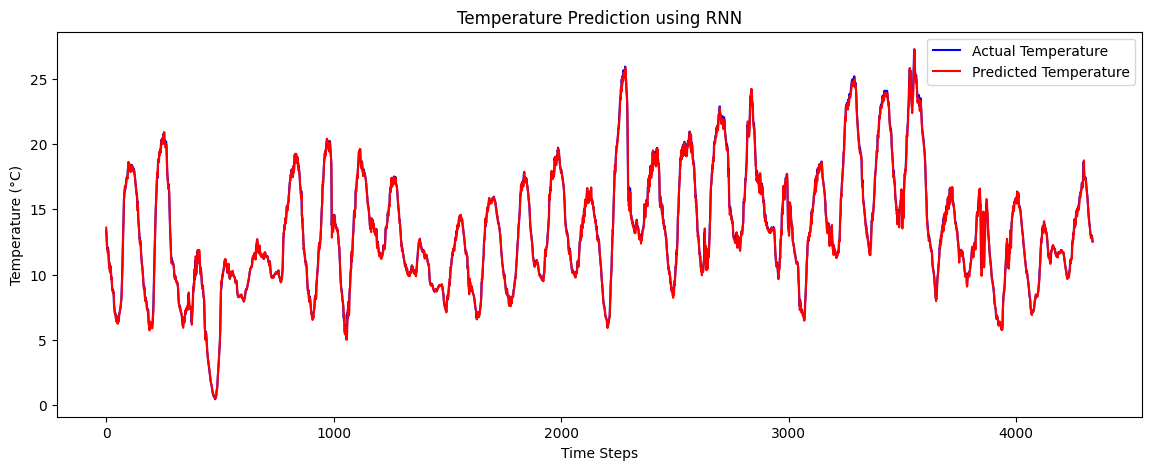

In [16]:
# 6. 시각화
plt.figure(figsize=(14, 5))  # 그래프 크기 설정 (가로 14, 세로 5)

plt.plot(actual_values, label="Actual Temperature", color='blue')
# Actual(액추얼): 실제 기온 / 파란색 선

plt.plot(predictions, label="Predicted Temperature", color='red')
# Predicted(프리딕티드): 예측 기온 / 빨간색 선

plt.title('Temperature Prediction using RNN')  # 그래프 제목
plt.xlabel('Time Steps')  # X축: 시간 순서
plt.ylabel('Temperature (°C)')  # Y축: 기온(섭씨)

plt.legend()  # 범례: 실제값과 예측값 구분
plt.show()   # 그래프 화면에 표시

# 🍔 실제 요리와 예측 요리를 나란히 놓고 차이를 비교하는 단계

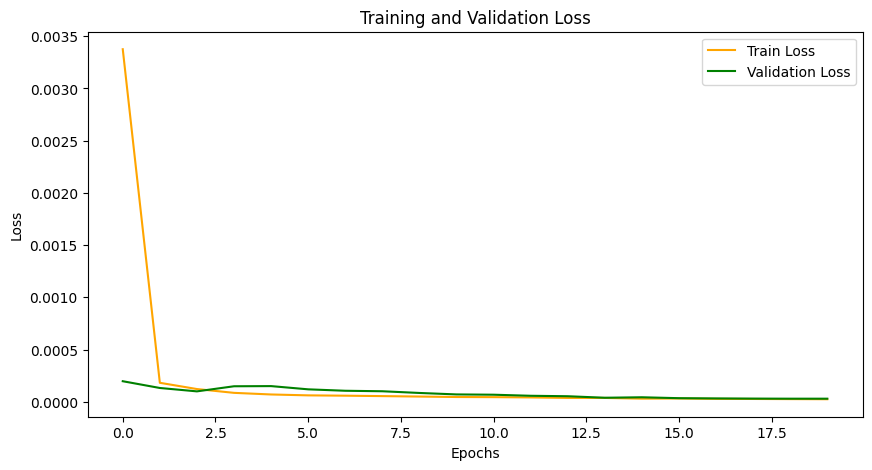

In [17]:
# 7. 학습 손실 시각화
plt.figure(figsize=(10, 5))  # 그래프 크기 설정

plt.plot(history.history['loss'], label='Train Loss', color='orange')
# Train Loss(트레인 로스): 학습 데이터의 오차

plt.plot(history.history['val_loss'], label='Validation Loss', color='green')
# Validation Loss(밸리데이션 로스): 검증 데이터의 오차

plt.title('Training and Validation Loss')  # 그래프 제목
plt.xlabel('Epochs')  # 에포크: 학습 반복 횟수
plt.ylabel('Loss')  # 손실: 예측 오차
plt.legend()  # 범례 표시
plt.show()  # 그래프 출력

# 🍔 연습할 때와 실전 테스트할 때 점수가 어떻게 달라지는지 비교